# Antiguide Propagation

The term Antiguide refers to a 3 layer guide with a central refractive index of lower value than it's outer refractive index.  Such guides do not support guided modes and can only propagate energy in the radiation field.  Since the slab package calculates the radiation field, it is well-suited to modeling this guide.  

This tutorial calculates the field induced such a guide by a truncated parabolic input field.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour, Plot3D

plt.style.use('dark_background')
%matplotlib widget

To initialize the guide, we pass the Slab class a list of refractive indices on each region:

In [2]:
A = Slab(ns=[1.44, 1, 1.44], xrefs=[400, 250, 400], wl=1e-6)

Note that the middle refractive index is lower than the outer values:

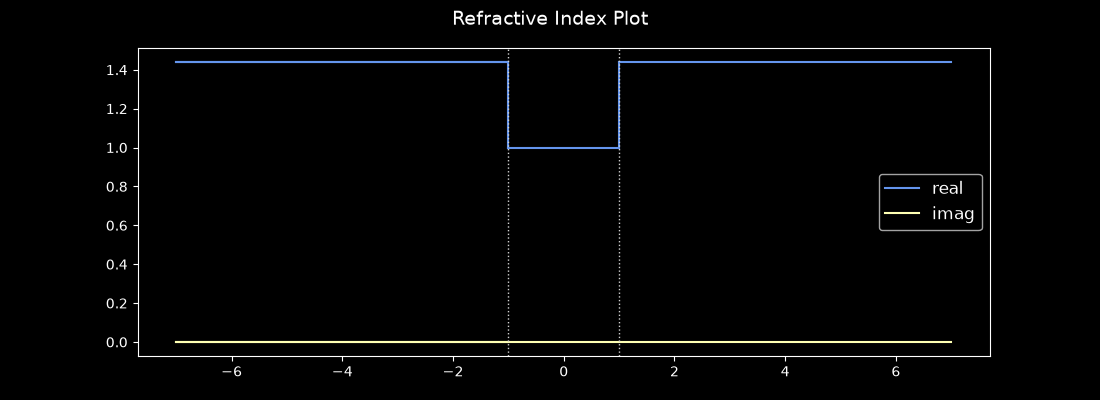

In [3]:
A.plot_refractive_index();

We asserted that this structure has no guided modes.  To verify this we plot the eigenvalue function:


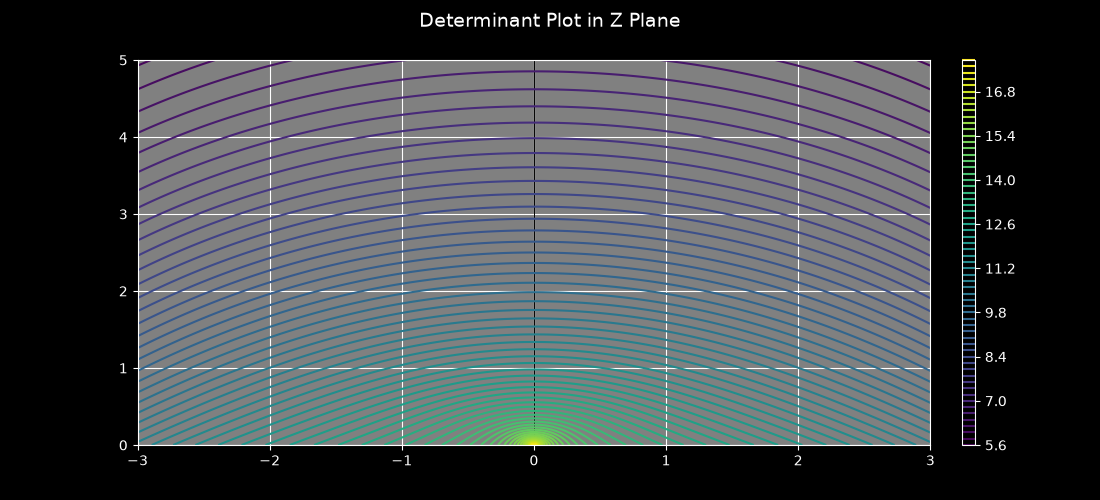

In [4]:
A.eigenvalue_plot(-3, 3, 0, 5);
# plt.show();

We now define our input field.

In [5]:
half_width = .5
shift = .25
amplitude = 1.

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

f0 = quadratic_piecewise

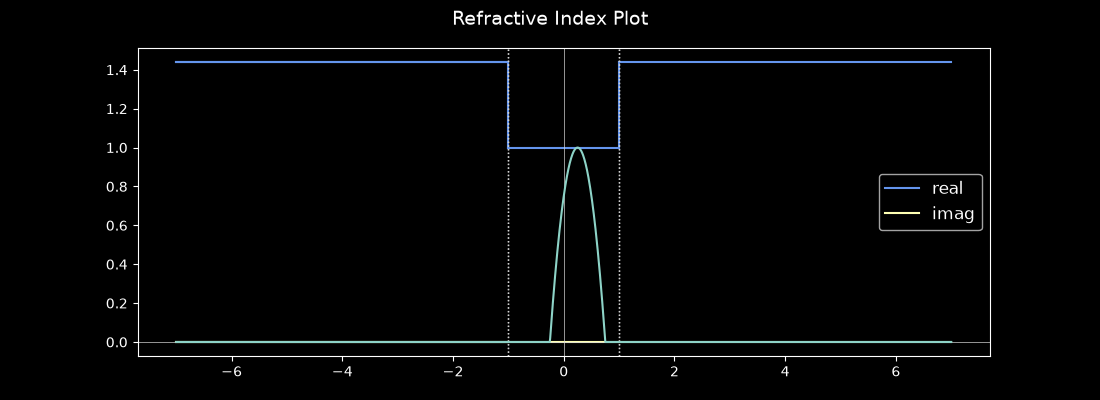

In [6]:
A.plot_refractive_index()
A.add_1d_plot(f0)

Next we initialize a propagator to calculate the field inside the guide from the input defined above:

In [7]:
P = Propagator(A, f0=f0, window=[Lx,Rx])

Now we begin integrating along the real line by adding contours:

In [8]:
P.add_contour(real_contour(.00001, A.Z_evanescent.real, 200))

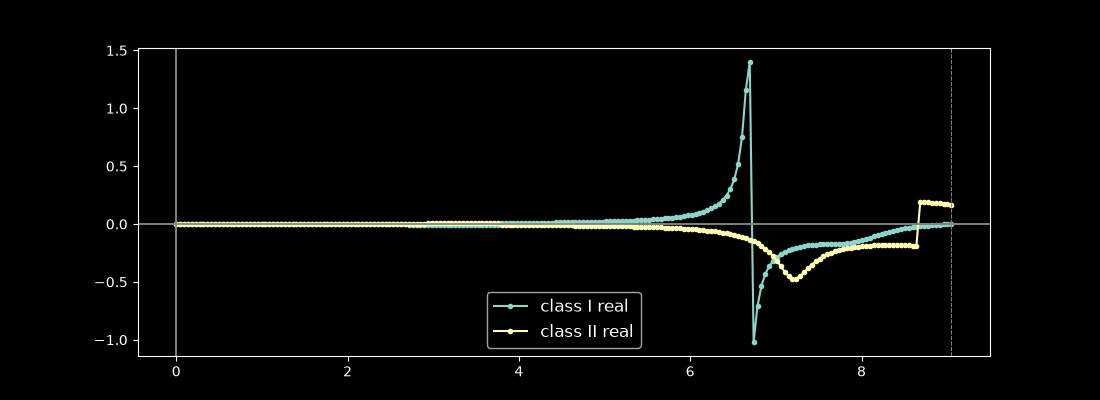

In [9]:
P.plot_transform();

There is a region with sharp variation, so we add a contour there with more sample points:

In [10]:
P.add_contour(real_contour(6.5, 6.9, 100))

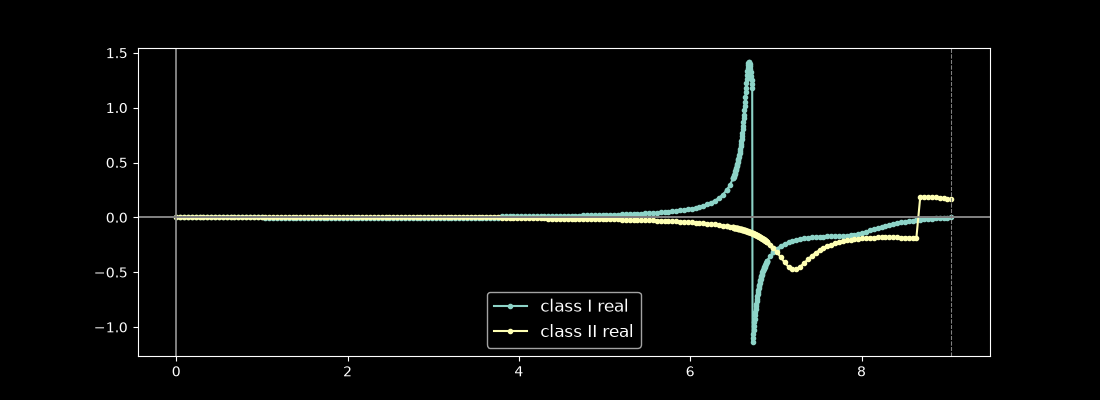

In [11]:
P.plot_transform();

We note that this radiation transform has a distinct spike near 6.8, a feature we will return to in later notebooks.  Now we continue to integrate past the point where the radiation modes become evanescent:

In [12]:
P.add_contour(real_contour(A.Z_evanescent.real, 4*A.Z_evanescent.real, 200))

In [13]:
P.plot_transform();

We now check to see if we have captured the input profile:

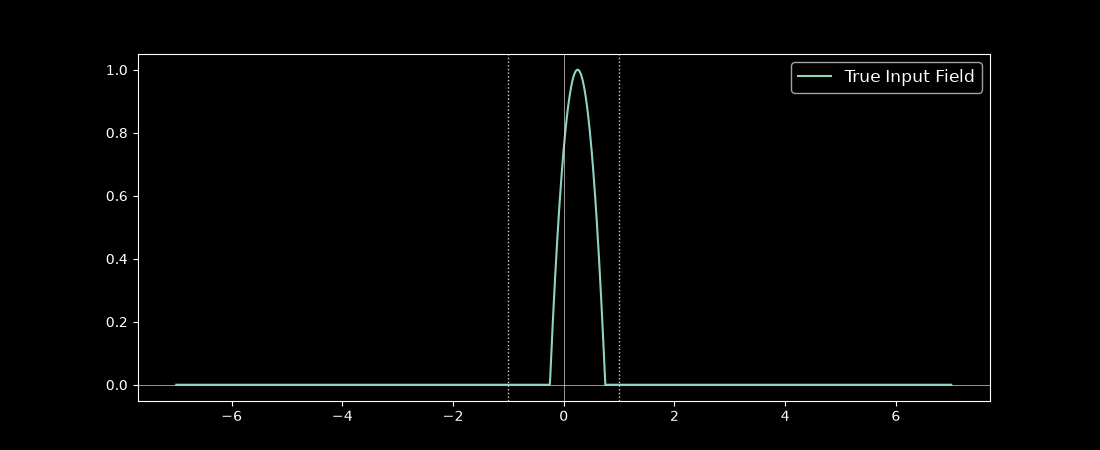

In [14]:
A.plot_field_1d(f0, label='True Input Field', figsize=(11,4.5));
A.add_1d_plot(P, ls='--',  lw=1, label='Propagated Field');

We have captured the input field to our desired level of resolution.  Now we visualize the full field in 2D:

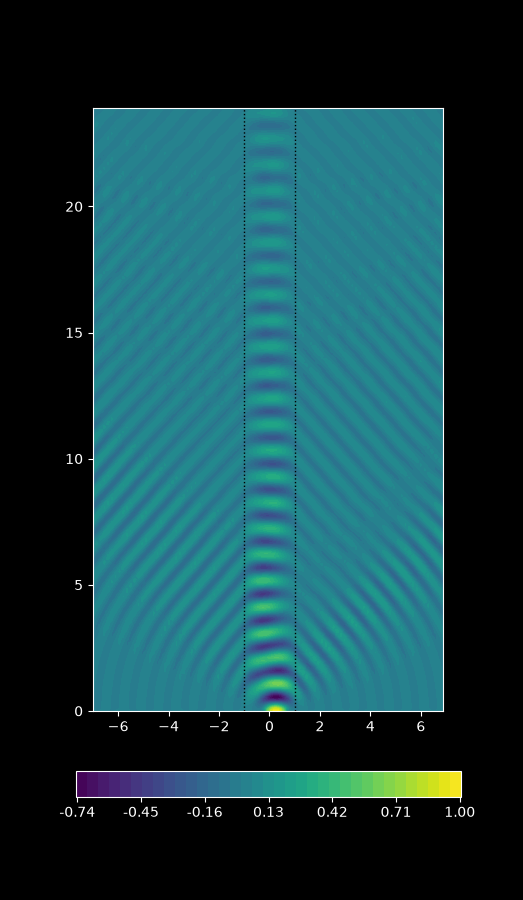

In [15]:
A.plot_field_2d(P, zmax=24, zref=240);

And we can view the field as a surface in 3D:

In [16]:
Plot3D(P, xstride=3);

<slabguide.plotting.Plot3D.Plot3D.<locals>.HelloWidget object at 0x7c6fe58f3e60>

And we can view the breakdown of the radiation field into it's propagating and evanescent parts:

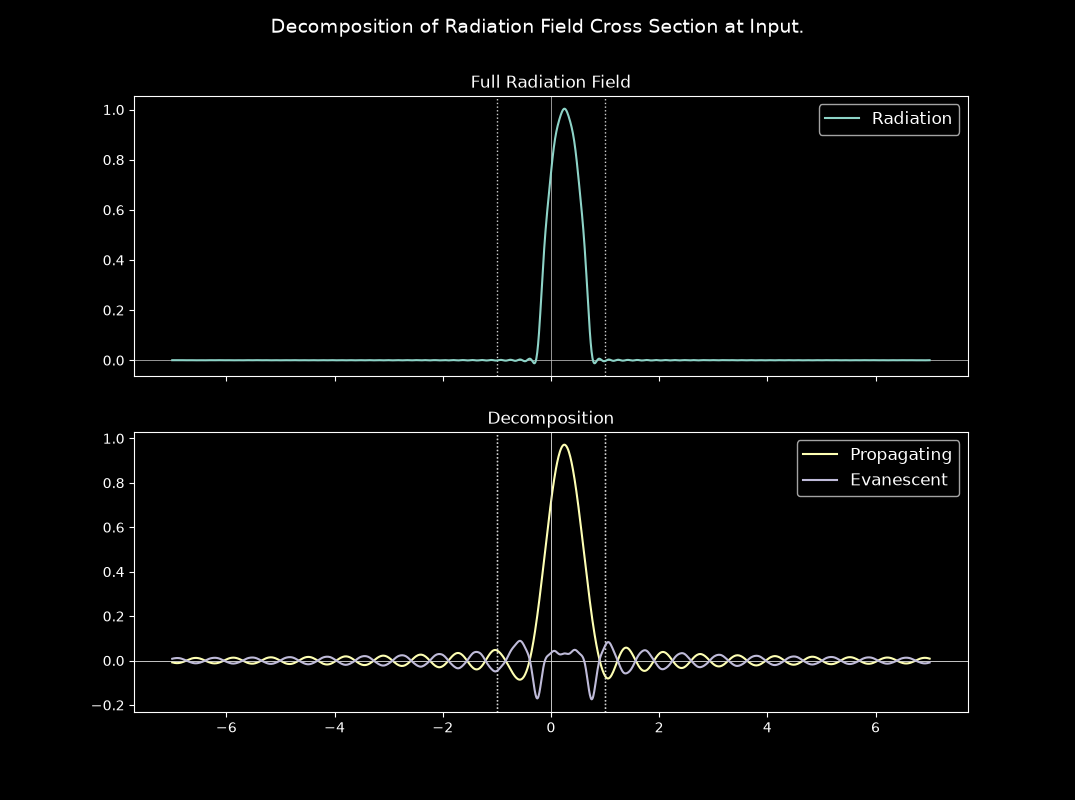

In [21]:
plt.close('all')
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10.75, 8))
fig.suptitle('Decomposition of Radiation Field Cross Section at Input.\n', fontsize=14);

A.add_1d_plot(P.Radiation, ax=ax1, c='C0', label='Radiation');
ax1.set_title('Full Radiation Field')
A.add_1d_plot(P.Propagating, ax=ax2, c='C1', label='Propagating');
A.add_1d_plot(P.Evanescent, ax=ax2, c='C2', label='Evanescent');
ax2.set_title('Decomposition');
plt.show();

# Conclusion

In contrast to the basic 3 layer guide with high index core region, the antiguide propagates energy only in the radiation field.  It therefore has no guided field to calculate or visualize, and any power propagating in the core region is quickly lost to the surroundings, as we can infer from the 2D plot of the full field.  These facts make modeling the fields in these guides the ideal subject for introducing the leaky mode representation of the radiation field, which is the subject of notebook 2.1.